# **Aprendizaje por refuerzos** - FrozenLake y LunarLander (Gymnasium)

## Tarea: Implementar Agentes Q-Learning y DQN

### Objetivos:
1. Implementar el algoritmo Q-Learning
2. Implementar el algoritmo DQN
3. Entrenar y evaluar ambos agentes
4. Comparar el rendimiento de ambos enfoques


In [747]:
# Instalar paquetes requeridos
import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

%pip install swig matplotlib gymnasium torch pygame pandas seaborn --quiet

13171.75s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


In [748]:
# Importar las bibliotecas
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pygame
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import deque, namedtuple
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

La siguiente celda permite ejecutar un juego de Frozen Lake *determinista* para jugar con el teclado.

Utilize las teclas de dirección (flechas) o asdw para comandar al agente.


In [749]:
def jugar_frozen_lake(env):
    env.reset()
    
    print("Controles:")
    print("W - Arriba")
    print("S - Abajo") 
    print("A - Izquierda")
    print("D - Derecha")
    print("Q - Salir")
    print("Presione cualquier tecla para empezar...")
    
    pygame.init()
    pygame.display.set_caption("FrozenLake - Juego Interactivo")
    
    clock = pygame.time.Clock()
    ejecutando = True
    
    while ejecutando:
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                ejecutando = False
            elif event.type == pygame.KEYDOWN:
                if event.key == pygame.K_q or event.key == pygame.K_ESCAPE:
                    ejecutando = False
                elif event.key == pygame.K_w or event.key == pygame.K_UP:
                    accion = 3  # Arriba
                elif event.key == pygame.K_s or event.key == pygame.K_DOWN:
                    accion = 1  # Abajo
                elif event.key == pygame.K_a or event.key == pygame.K_LEFT:
                    accion = 0  # Izquierda
                elif event.key == pygame.K_d or event.key == pygame.K_RIGHT:
                    accion = 2  # Derecha
                else:
                    continue
                
                observacion, recompensa, terminado, truncado, info = env.step(accion)
                print(f"Acción: {accion}, Recompensa: {recompensa}, Terminado: {terminado}")
                
                if terminado or truncado:
                    print(f"¡Episodio terminado! Recompensa final: {recompensa}")
                    pygame.time.wait(500)
                    env.reset()
        
        clock.tick(60)
    
    pygame.quit()
    env.close()

env = gym.make('FrozenLake-v1', render_mode='human', is_slippery=False)
# Descomente la línea de abajo para jugar interactivamente
#jugar_frozen_lake(env)

La siguiente celda permite jugar al juego no determinista.

In [750]:
env = gym.make('FrozenLake-v1', map_name="4x4", render_mode='human', is_slippery=True)
# Descomente la línea de abajo para jugar interactivamente
#jugar_frozen_lake(env)

La siguiente clase define la interfaz de los agentes que utilizaremos para jugar al Frozen Lake.


In [751]:
from abc import ABC, abstractmethod

class Agente(ABC):
    
    @abstractmethod
    def elegir_accion(self, estado):
        """Elige una acción dada una observación."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar."""
    
    def __init__(self, espacio_acciones):
        # Se guarda el espacio de acciones para poder elegir acciones al azar
        self.espacio_acciones = espacio_acciones
    
    def elegir_accion(self, estado):
        return self.espacio_acciones.sample()


    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende

# Probar el AgenteAleatorio
env = gym.make('FrozenLake-v1')
agente_aleatorio = AgenteAleatorio(env.action_space)
estado, _ = env.reset()
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()


✓ AgenteAleatorio creado y probado. Acción: 3


In [752]:
from abc import ABC, abstractmethod

class EpsilonStrategy(ABC):
    @abstractmethod
    def decay(self, step: float | None = None) -> float:
        pass

class EpsilonStrExp(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_rate=0.995):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_rate = decay_rate

    def decay(self) -> float:
        self.epsilon = max(self.epsilon_min, self.epsilon * self.decay_rate)
        return self.epsilon

class EpsilonStrLinear(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_steps=1000):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_steps = decay_steps

    def decay(self) -> float:
        self.epsilon = max(self.epsilon_min, self.epsilon - 1.0 / self.decay_steps)
        return self.epsilon

class EpsilonStrCosine(EpsilonStrategy):
    def __init__(self, epsilon=1.0, epsilon_min=0.1, decay_steps=1000):
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.decay_steps = decay_steps
        self.step = 0

    def decay(self) -> float:
        self.step += 1
        cosine_decay = 0.5 * (1 + np.cos(np.pi * self.step / self.decay_steps))
        self.epsilon = self.epsilon_min + (self.epsilon - self.epsilon_min) * cosine_decay
        return self.epsilon



La siguiente celda define una función para evaluar el desempeño de un agente dado.

In [753]:
# Función de Evaluación de Agentes
def evaluar_agente(agente, env, num_episodios=1000):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.
    
    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
    
    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    victorias = 0
    
    for episodio in range(num_episodios):
        estado, _ = env.reset()
        recompensa_total = 0
        
        while True:
            accion = agente.elegir_accion(estado)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa
            
            if terminado or truncado:
                break
        
        recompensas_totales.append(recompensa_total)
        if recompensa_total > 0:
            victorias += 1
    
    return {
        'recompensas_totales': recompensas_totales,
        'victorias': victorias,
        'tasa_victorias': victorias / num_episodios,
        'recompensa_promedio': np.mean(recompensas_totales),
        'desv_estandar': np.std(recompensas_totales)
    }

def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación de forma formateada."""
    print(f"\n{nombre_agente} - Resultados de Evaluación:")
    print(f"Tasa de Victorias: {resultados['tasa_victorias']:.1%}")
    print(f"Recompensa Promedio: {resultados['recompensa_promedio']:.3f}")
    print(f"Desviación Estándar: {resultados['desv_estandar']:.3f}")
    print(f"Total de Victorias: {resultados['victorias']}")

# Probar función de evaluación
env = gym.make('FrozenLake-v1')
agente_aleatorio = AgenteAleatorio(env.action_space)
resultados = evaluar_agente(agente_aleatorio, env, num_episodios=100)
imprimir_resultados_evaluacion(resultados, "Agente Aleatorio")
env.close()



Agente Aleatorio - Resultados de Evaluación:
Tasa de Victorias: 1.0%
Recompensa Promedio: 0.010
Desviación Estándar: 0.099
Total de Victorias: 1


La siguiente celda define una función para entrenar un agente.

In [754]:
# Función de Entrenamiento de Agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=500, verbose=True):
    """
    Entrena un agente en el entorno.
    
    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
    
    Returns:
        list: Recompensas de episodios
    """
    recompensas_episodios = []
    longitudes_episodios = []
    epsilons_episodios = []
    num_episodios_10 = int(num_episodios / 10)
    alphas_episodios = []
    
    for episodio in range(num_episodios):
        estado, _ = env.reset()
        recompensa_total = 0
        pasos = 0
        
        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado or truncado)
            
            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1
            
            if terminado or truncado:
                break
        
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        epsilons_episodios.append(agente.epsilon)
        if isinstance(agente, AgenteQLearning):
            alphas_episodios.append(agente.alpha)
        
        if verbose and (episodio + 1) % num_episodios_10 == 0:
            recompensa_promedio = np.mean(recompensas_episodios[-num_episodios_10:])
            longitud_promedio = np.mean(longitudes_episodios[-num_episodios_10:])
            epsilon_promedio = np.mean(epsilons_episodios[-num_episodios_10:])
            alpha_promedio = np.mean(alphas_episodios[-num_episodios_10:])
            print(f"Episodio {episodio + 1}: Recompensa Promedio = {recompensa_promedio:.3f}, Longitud Promedio = {longitud_promedio:.1f}, Epsilon Promedio = {epsilon_promedio:.3f}, Alpha Promedio = {alpha_promedio:.3f}")

    return recompensas_episodios, longitudes_episodios

print("✓ Funciones de entrenamiento definidas")



✓ Funciones de entrenamiento definidas


# QL TABULAR
## Q-Learning en entornos no deterministas

En entornos estocásticos, ejecutar una acción desde un estado no garantiza llegar siempre al mismo siguiente estado, ni recibir siempre la misma recompensa. Por eso, la actualización de la tabla Q se hace de manera **promediada**, usando un factor de aprendizaje α.

La fórmula clásica de actualización es:

$$
Q(s, a) \leftarrow (1-\alpha) Q(s, a) + \alpha \big[r + \gamma \max_{a'} Q(s', a')\big]
$$

- **α (tasa de aprendizaje):** determina cuánto peso le damos a la nueva información frente a lo aprendido hasta ahora.  
- **r + γ max Q(s', a'):** estimación de la recompensa total esperada al ejecutar la acción.
- En **entornos deterministas**, se puede sobrescribir Q(s, a) directamente porque la acción siempre lleva al mismo estado y recompensa.
- En **entornos no deterministas**, se necesita promediar la experiencia, ya que la acción puede llevar a distintos estados con distintas recompensas. El valor de Q converge así al **valor esperado a largo plazo** de cada acción.


In [755]:
class AgenteQLearning(Agente):
    """Agente que usa el algoritmo Q-Learning."""

    def __init__(self, espacio_estados, espacio_acciones, alpha=0.05, gamma=1, epsilon=1.0, epsilon_strategy: EpsilonStrategy = None):
        self.Q_table = np.zeros((espacio_estados.n, espacio_acciones.n))
        self.alpha = alpha  # Tasa de aprendizaje
        self.gamma = gamma  # Factor de descuento
        self.epsilon = epsilon  # Tasa de exploración inicial
        self.espacio_acciones = espacio_acciones
        self.tam_mapa = int(np.sqrt(espacio_estados.n))  
        self.epsilon_strategy = epsilon_strategy
        
    def elegir_accion(self, estado):
        """Elige una acción usando política epsilon-greedy.""" 
        if np.random.rand() < self.epsilon:
            return np.random.randint(4)  # Exploración
        else:
            return np.argmax(self.Q_table[estado])  # Explotación, accion que maximiza Q
    
            
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Actualiza la tabla Q usando la ecuación de Bellman."""
        max_q = np.max(self.Q_table[siguiente_estado])
        self.Q_table[estado, accion] = (1 - self.alpha) * self.Q_table[estado, accion] + self.alpha * (recompensa + self.gamma * max_q)
        if terminado:
            self.epsilon = self.epsilon_strategy.decay()

    def imprimirQtable(self):
        print("Tabla Q:")
        print(self.Q_table)

    def mostrar_policy(self, env):
        """
        Muestra la política aprendida en el mapa del FrozenLake.
        Flechas solo en casillas 'F' (Frozen); 'H' y 'G' se muestran tal cual.
        """
        # Mapeo de acciones a flechas: 0=izquierda, 1=abajo, 2=derecha, 3=arriba
        acciones_map = ["←", "↓", "→", "↑"]

        # Obtener el mapa original del entorno
        desc = env.unwrapped.desc.astype(str)

        # Crear copia del mapa para mostrar la política
        policy_map = desc.copy()

        # Recorrer filas y columnas del mapa
        for fila in range(self.tam_mapa):
            for col in range(self.tam_mapa):
                estado = fila * self.tam_mapa + col  # convertir fila,col a índice lineal
                if desc[fila, col] == 'F':  # solo actualizar casillas 'Frozen'
                    mejor_accion = np.argmax(self.Q_table[estado])
                    policy_map[fila, col] = acciones_map[mejor_accion]

        print("Policy aprendida:")
        for fila in policy_map:
            print(" ".join(fila))

    def guardar_qtable(self, path="qtable.npy"):
        np.save(path, self.Q_table)
        print(f"Q-table guardada en {path}")

    def cargar_qtable(self, path="qtable.npy"):
        self.Q_table = np.load(path)
        self.epsilon = 0  # Fijar epsilon al mínimo para evaluación
        print(f"Q-table cargada desde {path}")


# DQN

In [756]:

class DQN(nn.Module):
    """Clase auxiliar que implementa una Red Q Profunda con una capa oculta."""
    
    def __init__(self, tamano_entrada, tamano_oculto, tamano_salida):
        super(DQN, self).__init__()
        
        self.fc1 = nn.Linear(tamano_entrada, tamano_oculto)
        self.out = nn.Linear(tamano_oculto, tamano_salida)
    
    def forward(self, x):
        x = F.relu(self.fc1(x)) #Func. activación ReLU (Rectified Linear Unit)
        x = self.out(x)         #Capa final no usa activación
        return x                

class AgenteDQN(Agente):
    """Agente de Red Q Profunda."""
    
    def __init__(self,
                 espacio_estados,
                 espacio_acciones,
                 tamano_oculto=32,
                 lr=1e-3,
                 gamma=0.99,
                 epsilon=1.0,
                 replay_size=10000,
                 batch_size=128,
                 target_update=500,
                 train_freq=15,
                 epsilon_strategy: EpsilonStrategy = None,
                 device=None):
        """
        Args:
            espacio_estados: env.observation_space (discreto)
            espacio_acciones: env.action_space
            tamano_oculto: neuronas en la capa oculta
            lr: learning rate para el optimizador
            gamma: factor de descuento
            epsilon, epsilon_decay, epsilon_min: para epsilon-greedy
            replay_size: capacidad del buffer de replay
            batch_size: tamaño de batch para entrenar
            target_update: cada cuántos pasos copiar la target network
            train_freq: entrenar cada 'train_freq' llamadas a aprender
            device: 'cpu' o 'cuda' (None -> detecta automaticamente)
        """
        # parámetros del entorno
        self.num_states = espacio_estados.n
        self.num_actions = espacio_acciones.n
        
        # hiperparámetros
        self.tamano_oculto = tamano_oculto
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.batch_size = batch_size
        self.target_update = target_update
        self.train_freq = train_freq
        self.epsilon_strategy = epsilon_strategy
        
        # device
        if device is None:
            self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        else:
            self.device = torch.device("cpu")
        

        # redes: policy_net y target_net
        self.policy_net = DQN(self.num_states, self.tamano_oculto, self.num_actions).to(self.device)
        self.target_net = DQN(self.num_states, self.tamano_oculto, self.num_actions).to(self.device)
        
        # inicializar target igual a policy
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        
        # optimizador y loss
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=self.lr)
        self.loss_fn = nn.MSELoss()
        
        # replay buffer
        self.replay_buffer = deque(maxlen=replay_size)
        
        # contadores
        self.step_count = 0  # para updates y frecuencia de entrenamiento
        
        # semilla opcional
        random.seed(0)
        np.random.seed(0)
        torch.manual_seed(0)
    
    def _one_hot(self, estado):
        """Convierte un entero estado -> vector one-hot tensor en device."""
        vec = np.zeros(self.num_states, dtype=np.float32)
        vec[estado] = 1.0
        return torch.from_numpy(vec).to(self.device)
    
    def elegir_accion(self, estado):
        """Elige acción usando política epsilon-greedy."""
        # exploración
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.num_actions)
        
        # explotación: predecir Q-values y tomar argmax
        self.policy_net.eval()
        with torch.no_grad():
            s_t = self._one_hot(estado).unsqueeze(0)  # shape (1, num_states)
            q_vals = self.policy_net(s_t)            # shape (1, num_actions)
            accion = torch.argmax(q_vals, dim=1).item()
        self.policy_net.train()
        return accion
    
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """
        Agrega la transición al buffer y entrena la red periódicamente.
        Este método es llamado por el loop de entrenamiento por paso.
        """
        # almacenar transición (s, a, r, s', done)
        self.replay_buffer.append((estado, accion, recompensa, siguiente_estado, float(terminado)))
        self.step_count += 1
        
        # Entrenar cada 'train_freq' pasos (evita entrenar en cada transición)
        if (self.step_count % self.train_freq == 0) and (len(self.replay_buffer) >= self.batch_size):
            self._train_on_batch()
        
        # actualizar target network periódicamente
        if self.step_count % self.target_update == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
        
        # si terminó el episodio, actualizar epsilon (igual que en Q-table)
        if terminado:
            self.epsilon = self.epsilon_strategy.decay()
    
    def _train_on_batch(self):
        """Muestrea un minibatch y realiza un paso de optimización."""
        batch = random.sample(self.replay_buffer, self.batch_size)
        estados, acciones, recompensas, estados_siguientes, dones = zip(*batch)
        
        # convertir a tensores
        estados = torch.stack([self._one_hot(s) for s in estados])            # (B, num_states)
        estados_siguientes = torch.stack([self._one_hot(s) for s in estados_siguientes])  # (B, num_states)
        acciones = torch.tensor(acciones, dtype=torch.long, device=self.device)           # (B,)
        recompensas = torch.tensor(recompensas, dtype=torch.float32, device=self.device)  # (B,)
        dones = torch.tensor(dones, dtype=torch.float32, device=self.device)              # (B,)
        
        # Q(s,a) predichos por policy_net
        q_preds = self.policy_net(estados)                       # (B, num_actions)
        q_pred_values = q_preds.gather(1, acciones.unsqueeze(1)).squeeze(1)  # (B,)
        
        # target: r + gamma * max_a' Q_target(s', a')  (0 si done)
        with torch.no_grad():
            q_next = self.target_net(estados_siguientes)        # (B, num_actions)
            q_next_max, _ = q_next.max(dim=1)                  # (B,)
            q_targets = recompensas + (1.0 - dones) * (self.gamma * q_next_max)
        
        # loss y optimización
        loss = self.loss_fn(q_pred_values, q_targets)
        self.optimizer.zero_grad()
        loss.backward()
        # opcional: gradient clipping
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 10.0)
        self.optimizer.step()

    def mostrar_policy(self, env):
        acciones_map = ["←", "↓", "→", "↑"]
        desc = env.unwrapped.desc.astype(str)
        tam_mapa = int(np.sqrt(self.num_states))
        policy_map = desc.copy()
        
        self.policy_net.eval()
        with torch.no_grad():
            all_states = torch.eye(self.num_states, device=self.device)
            q_vals = self.policy_net(all_states)
            mejores = torch.argmax(q_vals, dim=1).cpu().numpy()
        self.policy_net.train()
        
        for fila in range(tam_mapa):
            for col in range(tam_mapa):
                estado = fila * tam_mapa + col
                if desc[fila, col] == 'F':
                    policy_map[fila, col] = acciones_map[mejores[estado]]
        
        print("Policy aprendida (DQN):")
        for fila in policy_map:
            print(" ".join(fila))    

    def guardar_policy(self, path="dqn_policy.pth"):
        torch.save(self.policy_net.state_dict(), path)
        print(f"Policy guardada en {path}")

    def cargar_policy(self, path="dqn_policy.pth"):
        self.policy_net.load_state_dict(torch.load(path, map_location=self.device))
        self.policy_net.eval()
        self.epsilon = 0  # Fijar epsilon al mínimo para evaluación
        print(f"Policy cargada desde {path}")

In [771]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gymnasium as gym

def test_params(tipo, alphas, decays, episodios_train, episodios_eval, map_name):
    resultados_exp = []
    resultados_lin = []

    # ======== Estrategia Exponencial ========
    for alpha in alphas:
        for decay in decays:
            #print(f"Probando con alpha={alpha}, decay={decay}")

            env = gym.make("FrozenLake-v1", map_name=map_name, is_slippery=True, render_mode="ansi", max_episode_steps=300)
            epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=0.01, decay_rate=decay)
            if tipo == "DQN":
                agente = AgenteDQN(env.observation_space, env.action_space, gamma=1, lr=alpha, epsilon_strategy=epsilon_strategy)
            else:
                agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=alpha, epsilon_strategy=epsilon_strategy)

            # Entrenar
            entrenar_agente(agente, env, num_episodios=episodios_train, verbose=False)
            # Evaluar
            resultados_eval = evaluar_agente(agente, env, num_episodios=episodios_eval)

            resultados_exp.append({
                "Estrategia": "Exponencial",
                "Alpha": alpha,
                "Lr": alpha,
                "Decay": decay,
                "Tasa de victoria": resultados_eval["tasa_victorias"],
                "Recompensa promedio": resultados_eval["recompensa_promedio"],
                "Desviación estándar": resultados_eval["desv_estandar"]
            })
            env.close()

    # ======== Estrategia Lineal ========
    for alpha in alphas:
        #print(f"Probando con alpha={alpha} y decay lineal")

        env = gym.make("FrozenLake-v1", map_name=map_name, is_slippery=True, render_mode="ansi", max_episode_steps=300)
        epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=0.01, decay_steps=episodios_train)
        if tipo == "DQN":
            agente = AgenteDQN(env.observation_space, env.action_space, gamma=1, lr=alpha, epsilon_strategy=epsilon_strategy)
        else:
            agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=alpha, epsilon_strategy=epsilon_strategy)

        # Entrenar
        entrenar_agente(agente, env, num_episodios=episodios_train, verbose=False)
        # Evaluar
        resultados_eval = evaluar_agente(agente, env, num_episodios=episodios_eval)

        resultados_lin.append({
            "Estrategia": "Lineal",
            "Alpha": alpha,
            "Lr": alpha,
            "Decay": "Lineal",
            "Tasa de victoria": resultados_eval["tasa_victorias"],
            "Recompensa promedio": resultados_eval["recompensa_promedio"],
            "Desviación estándar": resultados_eval["desv_estandar"]
        })
        env.close()

    # ======== Crear DataFrames ========
    df_exp = pd.DataFrame(resultados_exp)
    df_lin = pd.DataFrame(resultados_lin)

    return df_exp, df_lin


<h2 style="color: #228B22;">Entrenar Agente QL tabular</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

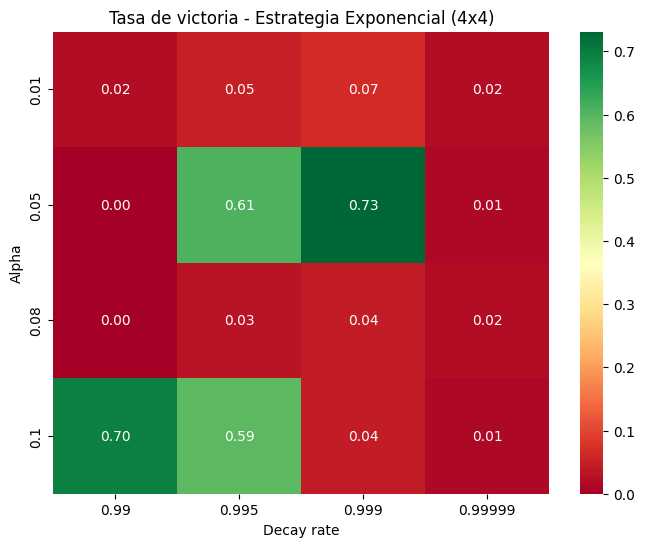

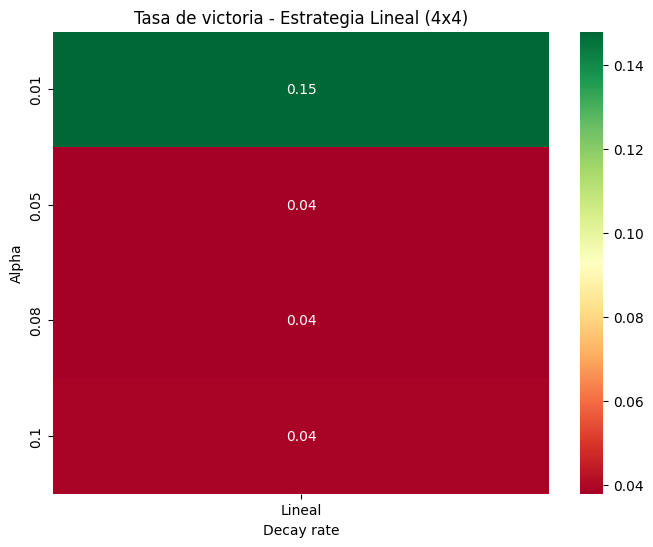


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial  0.010  0.990             0.021                0.021                0.143
Exponencial  0.010  0.995             0.050                0.050                0.218
Exponencial  0.010  0.999             0.066                0.066                0.248
Exponencial  0.010  1.000             0.021                0.021                0.143
Exponencial  0.050  0.990             0.000                0.000                0.000
Exponencial  0.050  0.995             0.606                0.606                0.489
Exponencial  0.050  0.999             0.731                0.731                0.443
Exponencial  0.050  1.000             0.014                0.014                0.117
Exponencial  0.100  0.990             0.696                0.696                0.460
Exponencial  0.100  0.995             0.592                0.592                0.491
Exponencial  0

In [758]:
alphas = [0.01, 0.05, 0.1, 0.08]
decays = [0.99, 0.995, 0.999, 0.99999]
episodios_train = 10000
episodios_eval = 1000
map_name = "4x4"

df_exp, df_lin = test_params("Q", alphas, decays, episodios_train, episodios_eval, map_name)

# ======== Heatmap de tasa de victorias exp ========
pivot = df_exp.pivot(index="Alpha", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Exponencial ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Alpha")
plt.show()

pivot = df_lin.pivot(index="Alpha", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Lineal ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Alpha")
plt.show()

# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))


In [759]:
# Entrenar  el Agente Q-Learning en FrozenLake-v1 4x4 

env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=300)
epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=0.01, decay_rate=0.999)
agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=0.05, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
resultados, longitudes = entrenar_agente(agente, env, num_episodios=20000, verbose=True)
agente.imprimirQtable()
agente.guardar_qtable("qtable_frozenlake_4x4.npy")
env.close()

Episodio 2000: Recompensa Promedio = 0.074, Longitud Promedio = 12.6, Epsilon Promedio = 0.432, Alpha Promedio = 0.050
Episodio 4000: Recompensa Promedio = 0.469, Longitud Promedio = 33.2, Epsilon Promedio = 0.058, Alpha Promedio = 0.050
Episodio 6000: Recompensa Promedio = 0.706, Longitud Promedio = 41.1, Epsilon Promedio = 0.011, Alpha Promedio = 0.050
Episodio 8000: Recompensa Promedio = 0.727, Longitud Promedio = 41.9, Epsilon Promedio = 0.010, Alpha Promedio = 0.050
Episodio 10000: Recompensa Promedio = 0.745, Longitud Promedio = 42.3, Epsilon Promedio = 0.010, Alpha Promedio = 0.050
Episodio 12000: Recompensa Promedio = 0.731, Longitud Promedio = 40.8, Epsilon Promedio = 0.010, Alpha Promedio = 0.050
Episodio 14000: Recompensa Promedio = 0.746, Longitud Promedio = 42.9, Epsilon Promedio = 0.010, Alpha Promedio = 0.050
Episodio 16000: Recompensa Promedio = 0.465, Longitud Promedio = 130.7, Epsilon Promedio = 0.010, Alpha Promedio = 0.050
Episodio 18000: Recompensa Promedio = 0.060

<h2 style="color: #228B22;">Evaluar Agente QL tabular</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

In [760]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
agente = AgenteQLearning(env.observation_space, env.action_space)
estado, _ = env.reset()
print(f"FrozenLake-v1 4x4: {env.render()}")
agente.cargar_qtable("qtable_frozenlake_4x4.npy")
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente Q-Learning")
agente.mostrar_policy(env)
env.close()

FrozenLake-v1 4x4: 
SFFF
FHFH
FFFH
HFFG

Q-table cargada desde qtable_frozenlake_4x4.npy

Agente Q-Learning - Resultados de Evaluación:
Tasa de Victorias: 0.0%
Recompensa Promedio: 0.000
Desviación Estándar: 0.000
Total de Victorias: 0
Policy aprendida:
S ↑ ↑ ↑
← H → H
↑ ↓ ← H
H → ↓ G


<h2 style="color: #228B22;">Entrenar Agente QL tabular</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

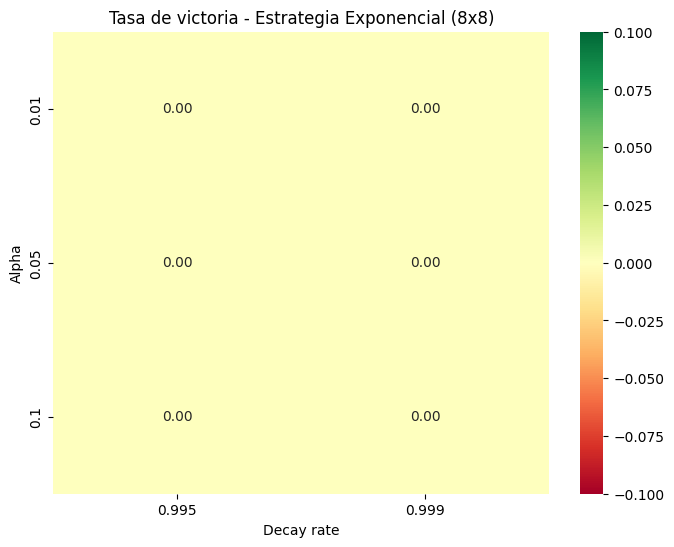

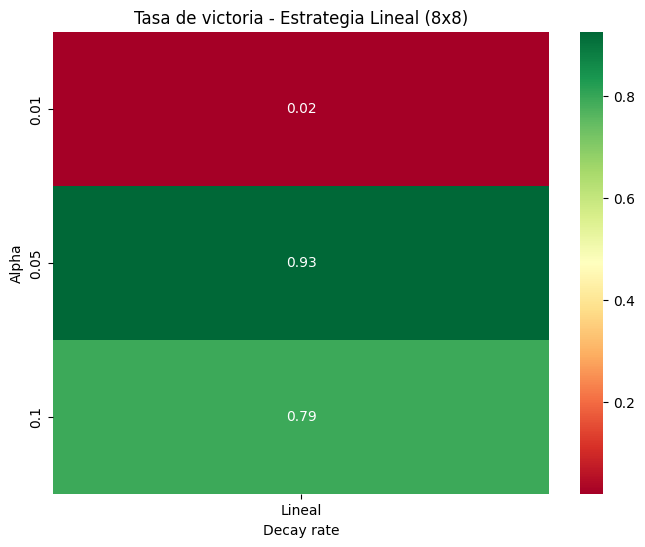


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial  0.010  0.995             0.000                0.000                0.000
Exponencial  0.010  0.999             0.000                0.000                0.000
Exponencial  0.050  0.995             0.000                0.000                0.000
Exponencial  0.050  0.999             0.000                0.000                0.000
Exponencial  0.100  0.995             0.000                0.000                0.000
Exponencial  0.100  0.999             0.000                0.000                0.000

📊 Resultados - Estrategia Lineal:
Estrategia  Alpha  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
    Lineal  0.010 Lineal             0.019                0.019                0.137
    Lineal  0.050 Lineal             0.926                0.926                0.262
    Lineal  0.100 Lineal             0.794                0.794     

In [761]:
alphas = [0.01, 0.05, 0.1]
decays = [0.995, 0.999]
episodios_train = 10000
episodios_eval = 1000
map_name = "8x8"

df_exp, df_lin = test_params("Q", alphas, decays, episodios_train, episodios_eval, map_name)
# ======== Heatmap de tasa de victorias exp ========
pivot = df_exp.pivot(index="Alpha", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Exponencial ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Alpha")
plt.show()

pivot = df_lin.pivot(index="Alpha", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Lineal ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Alpha")
plt.show()

# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))


In [ ]:
# Entrenar  Agente Q-Learning en FrozenLake-v1 8x8
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=0.01, decay_steps=20000)
agente = AgenteQLearning(env.observation_space, env.action_space, gamma=1, alpha=0.05, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
resultados, longitudes = entrenar_agente(agente, env, num_episodios=20000, verbose=True)
agente.imprimirQtable()
agente.guardar_qtable("qtable_frozenlake_8x8.npy")
env.close()

Episodio 2000: Recompensa Promedio = 0.004, Longitud Promedio = 32.8, Epsilon Promedio = 0.950, Alpha Promedio = 0.100
Episodio 4000: Recompensa Promedio = 0.005, Longitud Promedio = 38.7, Epsilon Promedio = 0.850, Alpha Promedio = 0.100
Episodio 6000: Recompensa Promedio = 0.010, Longitud Promedio = 41.9, Epsilon Promedio = 0.750, Alpha Promedio = 0.100
Episodio 8000: Recompensa Promedio = 0.028, Longitud Promedio = 51.3, Epsilon Promedio = 0.650, Alpha Promedio = 0.100
Episodio 10000: Recompensa Promedio = 0.048, Longitud Promedio = 60.1, Epsilon Promedio = 0.550, Alpha Promedio = 0.100
Episodio 12000: Recompensa Promedio = 0.091, Longitud Promedio = 70.6, Epsilon Promedio = 0.450, Alpha Promedio = 0.100
Episodio 14000: Recompensa Promedio = 0.175, Longitud Promedio = 83.5, Epsilon Promedio = 0.350, Alpha Promedio = 0.100
Episodio 16000: Recompensa Promedio = 0.313, Longitud Promedio = 99.9, Epsilon Promedio = 0.250, Alpha Promedio = 0.100
Episodio 18000: Recompensa Promedio = 0.070,

<h2 style="color: #228B22;">Evaluar Agente QL tabular</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

In [763]:
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
agente = AgenteQLearning(env.observation_space, env.action_space)
estado, _ = env.reset()
print(f"FrozenLake-v1 8x8: {env.render()}")
agente.cargar_qtable("qtable_frozenlake_8x8.npy")
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente Q-Learning")
agente.mostrar_policy(env)
env.close()

FrozenLake-v1 8x8: 
SFFFFFFF
FFFFFFFF
FFFHFFFF
FFFFFHFF
FFFHFFFF
FHHFFFHF
FHFFHFHF
FFFHFFFG

Q-table cargada desde qtable_frozenlake_8x8.npy

Agente Q-Learning - Resultados de Evaluación:
Tasa de Victorias: 12.1%
Recompensa Promedio: 0.121
Desviación Estándar: 0.326
Total de Victorias: 121
Policy aprendida:
S ← ← ← ← ← ← ←
↑ ↑ ↑ ↑ ↑ ↑ ↑ ←
↑ ← ← H → ↑ ↑ →
← ↑ ← ↑ ← H → →
↑ ↑ ← H → → ↑ →
← H H ↓ ↑ ← H →
↑ H ↑ ↑ H ← H →
← ← ↓ H ↓ ↑ ↓ G


<h2 style="color: #e66666ff;">Entrenar Agente DQN</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

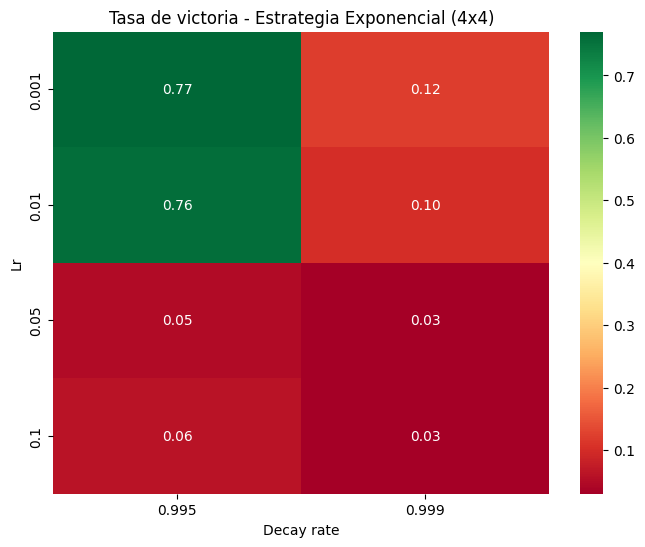

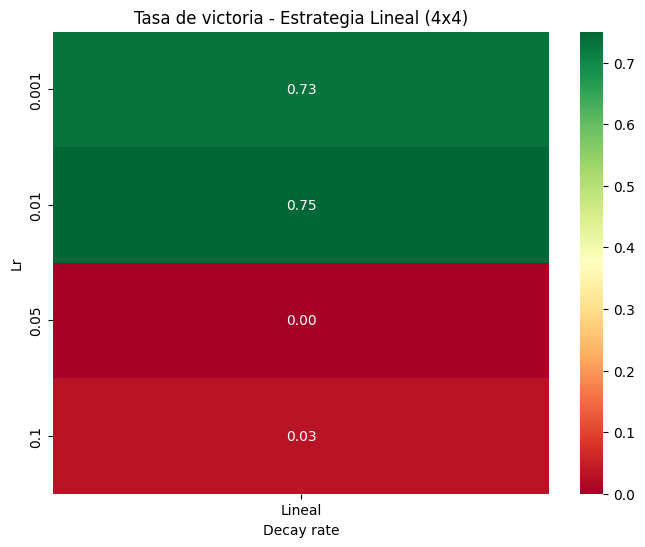


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha    Lr  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial  0.100 0.100  0.995             0.060                0.060                0.237
Exponencial  0.100 0.100  0.999             0.030                0.030                0.171
Exponencial  0.050 0.050  0.995             0.050                0.050                0.218
Exponencial  0.050 0.050  0.999             0.030                0.030                0.171
Exponencial  0.010 0.010  0.995             0.760                0.760                0.427
Exponencial  0.010 0.010  0.999             0.100                0.100                0.300
Exponencial  0.001 0.001  0.995             0.770                0.770                0.421
Exponencial  0.001 0.001  0.999             0.120                0.120                0.325

📊 Resultados - Estrategia Lineal:
Estrategia  Alpha    Lr  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
    Li

In [773]:
lrs = [0.1, 0.05, 0.01, 0.001]
decays = [0.995, 0.999]
episodios_train = 1000
episodios_eval = 100
map_name = "4x4"

df_exp, df_lin = test_params("DQN", lrs, decays, episodios_train, episodios_eval, map_name)
# ======== Heatmap de tasa de victorias exp ========
pivot = df_exp.pivot(index="Lr", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Exponencial ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Lr")
plt.show()

pivot = df_lin.pivot(index="Lr", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Lineal ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Lr")
plt.show()

# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))


In [774]:
# Entrenar y Evaluar el Agente DQN en FrozenLake-v1 4x4 
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
epsilon_strategy = EpsilonStrExp(epsilon=1.0, epsilon_min=0.01, decay_rate=0.999)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=16, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
print(f"FrozenLake-v1 4x4: {env.render()}")
resultados, longitudes = entrenar_agente(agente, env, num_episodios=20000, verbose=True)
agente.guardar_policy("dqn_policy_frozenlake_4x4.pth")
env.close()

FrozenLake-v1 4x4: 
SFFF
FHFH
FFFH
HFFG



/home/hezek/miniconda3/envs/pytorch-rocm/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/hezek/miniconda3/envs/pytorch-rocm/lib/python3.10/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Episodio 2000: Recompensa Promedio = 0.119, Longitud Promedio = 15.8, Epsilon Promedio = 0.432, Alpha Promedio = nan
Episodio 4000: Recompensa Promedio = 0.561, Longitud Promedio = 38.1, Epsilon Promedio = 0.058, Alpha Promedio = nan
Episodio 6000: Recompensa Promedio = 0.735, Longitud Promedio = 45.7, Epsilon Promedio = 0.011, Alpha Promedio = nan
Episodio 8000: Recompensa Promedio = 0.772, Longitud Promedio = 45.7, Epsilon Promedio = 0.010, Alpha Promedio = nan


KeyboardInterrupt: 

<h2 style="color: #e66666ff;">Evaluar Agente DQN</h2>
<h3 style="color: #22728bff;">Frozen Lake 4x4</h3>

In [ ]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=16)
agente.cargar_policy("dqn_policy_frozenlake_4x4.pth")
estado, _ = env.reset()
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente  DQN")
agente.mostrar_policy(env)
env.close()

/tmp/ipykernel_6393/403652709.py:189: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.policy_net.load_state_dict(torch.load(path, map_location=self.device))


Policy cargada desde dqn_policy_frozenlake_4x4.pth

Agente  DQN - Resultados de Evaluación:
Tasa de Victorias: 81.3%
Recompensa Promedio: 0.813
Desviación Estándar: 0.390
Total de Victorias: 813
Policy aprendida (DQN):
S ↑ ↑ ↑
← H ← H
↑ ↓ ← H
H → ↓ G


<h2 style="color: #e66666ff;">Entrenar Agente DQN</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

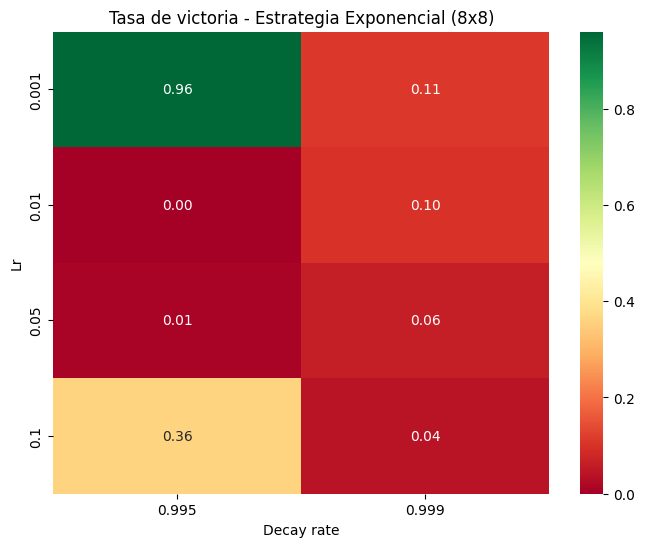

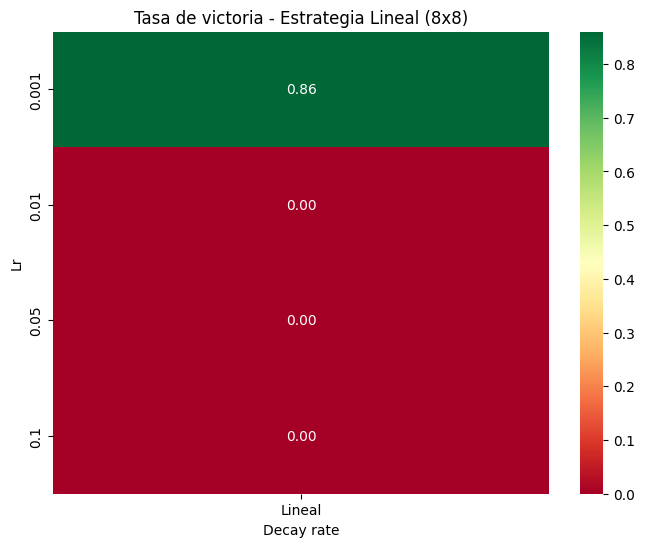


📊 Resultados - Estrategia Exponencial:
 Estrategia  Alpha    Lr  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
Exponencial  0.100 0.100  0.995             0.360                0.360                0.480
Exponencial  0.100 0.100  0.999             0.040                0.040                0.196
Exponencial  0.050 0.050  0.995             0.010                0.010                0.099
Exponencial  0.050 0.050  0.999             0.060                0.060                0.237
Exponencial  0.010 0.010  0.995             0.000                0.000                0.000
Exponencial  0.010 0.010  0.999             0.100                0.100                0.300
Exponencial  0.001 0.001  0.995             0.960                0.960                0.196
Exponencial  0.001 0.001  0.999             0.110                0.110                0.313

📊 Resultados - Estrategia Lineal:
Estrategia  Alpha    Lr  Decay  Tasa de victoria  Recompensa promedio  Desviación estándar
    Li

In [775]:
lrs = [0.1, 0.05, 0.01, 0.001]
decays = [0.995, 0.999]
episodios_train = 1000
episodios_eval = 100
map_name = "8x8"

df_exp, df_lin = test_params("DQN", lrs, decays, episodios_train, episodios_eval, map_name)
# ======== Heatmap de tasa de victorias exp ========
pivot = df_exp.pivot(index="Lr", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Exponencial ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Lr")
plt.show()

pivot = df_lin.pivot(index="Lr", columns="Decay", values="Tasa de victoria")

plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, cmap="RdYlGn", fmt=".2f")
plt.title(f"Tasa de victoria - Estrategia Lineal ({map_name})")
plt.xlabel("Decay rate")
plt.ylabel("Lr")
plt.show()

# ======== Mostrar resultados ========
print("\n📊 Resultados - Estrategia Exponencial:")
print(df_exp.to_string(index=False, float_format="%.3f"))

print("\n📊 Resultados - Estrategia Lineal:")
print(df_lin.to_string(index=False, float_format="%.3f"))


In [776]:
# Entrenar y Evaluar el Agente DQN en FrozenLake-v1 8x8
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
epsilon_strategy = EpsilonStrLinear(epsilon=1.0, epsilon_min=0.01, decay_steps=20000)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=32, epsilon_strategy=epsilon_strategy)
estado, _ = env.reset()
print(f"FrozenLake-v1 8x8: {env.render()}")
resultados, longitudes = entrenar_agente(agente, env, num_episodios=20000, verbose=True)
agente.guardar_policy("dqn_policy_frozenlake_8x8.pth")
env.close()

#9min.40s GPU
#2min.58s CPU

FrozenLake-v1 8x8: 
SFFFFFFF
FFFFFFFF
FFFHFFFF
FFFFFHFF
FFFHFFFF
FHHFFFHF
FHFFHFHF
FFFHFFFG



/home/hezek/miniconda3/envs/pytorch-rocm/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/hezek/miniconda3/envs/pytorch-rocm/lib/python3.10/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Episodio 2000: Recompensa Promedio = 0.004, Longitud Promedio = 33.7, Epsilon Promedio = 0.950, Alpha Promedio = nan
Episodio 4000: Recompensa Promedio = 0.007, Longitud Promedio = 38.3, Epsilon Promedio = 0.850, Alpha Promedio = nan


KeyboardInterrupt: 

<h2 style="color: #e66666ff;">Evaluar Agente DQN</h2>
<h3 style="color: #8e5bc0ff;">Frozen Lake 8x8</h3>

In [ ]:
env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, render_mode="ansi",  max_episode_steps=500)
agente = AgenteDQN(env.observation_space, env.action_space, tamano_oculto=32)
agente.cargar_policy("dqn_policy_frozenlake_8x8.pth")
estado, _ = env.reset()
resultados = evaluar_agente(agente, env, num_episodios=1000)
imprimir_resultados_evaluacion(resultados, "Agente  DQN")
agente.mostrar_policy(env)
env.close()

Policy cargada desde dqn_policy_frozenlake_8x8.pth


/tmp/ipykernel_6076/2936929551.py:192: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.policy_net.load_state_dict(torch.load(path, map_location=self.device))



Agente  DQN - Resultados de Evaluación:
Tasa de Victorias: 97.2%
Recompensa Promedio: 0.972
Desviación Estándar: 0.165
Total de Victorias: 972
Policy aprendida (DQN):
S ↑ → ↑ ↑ → → ←
↑ ↑ ↑ ↑ ↑ ↑ → ↓
↑ ↑ ← H → ↑ → →
← ↑ ← ↑ ← H → →
← ↑ ↑ H → ↓ ↑ →
← H H ↓ ↑ ← H →
← H ↓ ← H ← H →
← ↓ → H ↓ → ↓ G
